# ERCOT Hourly Load — Exploratory Data Analysis

This notebook explores the cleaned **2019–2025 ERCOT hourly-load dataset** and supports the later forecasting and capacity-adequacy analysis.

**Objectives**

1. Validate the processed dataset before beginning the analysis.
2. Examine long-term ERCOT load trends from 2019 to 2025.
3. Identify annual, monthly, day-of-week, and intraday load patterns.
4. Investigate annual peaks and sustained high-demand events.
5. Identify regional growth and coincident peak contributions relevant to forecasting and capacity planning.

**Input:** `data/processed/ercot_hourly_load_2019_2025.parquet`, generated in Notebook 01.  
**Outputs:** exploratory CSV tables and PNG figures under `report/`.  
**Execution:** run cells top to bottom from the project root or `notebooks/` directory; install dependencies using the project's `requirements.txt` before running.

> The results below are descriptive historical findings. They do not, by themselves, establish causal relationships or forecast future ERCOT operations.


In [31]:
# Import dependencies and configure display formatting for load and summary tables.

from pathlib import Path

import pandas as pd

pd.set_option(
    "display.max_columns",
    100,
)

pd.set_option(
    "display.float_format",
    lambda value: f"{value:,.3f}",
)


In [32]:
# Locate the project root and the cleaned Parquet dataset created by Notebook 01.
# Supports execution from either the repository root or its `notebooks/` subfolder.

current_directory = Path.cwd().resolve()

if (current_directory / "data").exists():
    project_root = current_directory
else:
    project_root = current_directory.parent

processed_data_path = (
    project_root
    / "data"
    / "processed"
    / "ercot_hourly_load_2019_2025.parquet"
)

if not processed_data_path.exists():
    raise FileNotFoundError(
        f"Processed dataset not found: "
        f"{processed_data_path.relative_to(project_root).as_posix()}"
    )

print("Project root:", "<repository root>")

print("Processed data:", processed_data_path.relative_to(project_root).as_posix())


Project root: <project root>
Processed data: data/processed/ercot_hourly_load_2019_2025.parquet


In [33]:
# Read the validated 2019–2025 hourly load dataset and inspect its first records.

load_data = pd.read_parquet(
    processed_data_path,
    engine="pyarrow",
)

print(
    "Dataset shape:",
    load_data.shape,
)

display(
    load_data.head(5)
)


Dataset shape: (61368, 20)


,HourEnding,COAST,EAST,FWEST,NORTH,NCENT,SOUTH,SCENT,WEST,ERCOT,HourEnding_raw,is_dst_label,HourEnding_local,interval_id,source_year,HourEnding_utc,calculated_ercot_mw,ercot_difference_mw,zone_total_mismatch_flag,global_interval_id
0,01/01/2019 01:00,"9,783.595","1,264.194","3,164.721",827.759,"11,697.766","3,066.891","5,993.974","1,282.543","37,081.443",01/01/2019 01:00,False,2019-01-01 01:00:00,1,2019,2019-01-01 07:00:00+00:00,"37,081.443",0.000,False,1
1,01/01/2019 02:00,"9,726.062","1,270.494","3,178.951",830.256,"11,787.936","3,140.383","6,029.774","1,295.133","37,258.990",01/01/2019 02:00,False,2019-01-01 02:00:00,2,2019,2019-01-01 08:00:00+00:00,"37,258.990",-0.000,False,2
2,01/01/2019 03:00,"9,654.374","1,269.504","3,200.881",831.506,"11,861.628","3,137.721","6,043.349","1,301.225","37,300.188",01/01/2019 03:00,False,2019-01-01 03:00:00,3,2019,2019-01-01 09:00:00+00:00,"37,300.188",0.000,False,3
3,01/01/2019 04:00,"9,631.735","1,243.168","3,221.963",839.690,"11,989.105","3,105.497","6,086.408","1,305.976","37,423.543",01/01/2019 04:00,False,2019-01-01 04:00:00,4,2019,2019-01-01 10:00:00+00:00,"37,423.543",0.000,False,4
4,01/01/2019 05:00,"9,698.889","1,309.573","3,240.635",848.672,"12,219.106","3,078.256","6,180.940","1,319.141","37,895.212",01/01/2019 05:00,False,2019-01-01 05:00:00,5,2019,2019-01-01 11:00:00+00:00,"37,895.212",-0.000,False,5


In [34]:
# Check record coverage, UTC uniqueness/order, and zone-total mismatch flags before analysis.
# Zone-total mismatch flags are retained for later regional exclusions.

eda_startup_check = pd.Series({
    "row_count": len(load_data),
    "column_count": len(load_data.columns),
    "utc_start": load_data["HourEnding_utc"].min(),
    "utc_end": load_data["HourEnding_utc"].max(),
    "utc_is_unique": load_data["HourEnding_utc"].is_unique,
    "utc_is_sorted": (
        load_data["HourEnding_utc"]
        .is_monotonic_increasing
    ),
    "zone_total_mismatch_rows": int(
        load_data["zone_total_mismatch_flag"].sum()
    ),
}, name="value")

eda_startup_check


row_count                                       61368
column_count                                       20
utc_start                   2019-01-01 07:00:00+00:00
utc_end                     2026-01-01 06:00:00+00:00
utc_is_unique                                    True
utc_is_sorted                                    True
zone_total_mismatch_rows                           48
Name: value, dtype: object

## 2. Calendar and Time Features

Create calendar variables from the **start** of each local hourly interval (`HourEnding_local - 1 hour`). Retain `source_year` to avoid assigning an Hour Ending 24 record to the following analysis year. These fields support year, quarter, month, weekday/weekend, hour, and seasonal comparisons.


In [ ]:
# Derive local interval-start year, month, weekday, hour, weekend, and season features.
# Using local interval-start time prevents Hour Ending 24 from shifting the analysis year.

eda_data = load_data.copy()

eda_data["interval_start_local"] = (
    eda_data["HourEnding_local"]
    - pd.Timedelta(hours=1)
)

eda_data["year"] = eda_data[
    "source_year"
]

eda_data["quarter"] = (
    eda_data["interval_start_local"]
    .dt
    .quarter
)

eda_data["month"] = (
    eda_data["interval_start_local"]
    .dt
    .month
)

eda_data["month_name"] = (
    eda_data["interval_start_local"]
    .dt
    .month_name()
    .str[:3]
)

eda_data["day_of_week"] = (
    eda_data["interval_start_local"]
    .dt
    .dayofweek
)

eda_data["day_name"] = (
    eda_data["interval_start_local"]
    .dt
    .day_name()
)

eda_data["hour"] = (
    eda_data["interval_start_local"]
    .dt
    .hour
)

eda_data["is_weekend"] = (
    eda_data["day_of_week"]
    .isin([5, 6])
)

season_mapping = {
    12: "Winter",
    1: "Winter",
    2: "Winter",
    3: "Spring",
    4: "Spring",
    5: "Spring",
    6: "Summer",
    7: "Summer",
    8: "Summer",
    9: "Fall",
    10: "Fall",
    11: "Fall",
}

eda_data["season"] = (
    eda_data["month"]
    .map(season_mapping)
)

time_feature_columns = [
    "HourEnding_raw",
    "HourEnding_local",
    "interval_start_local",
    "year",
    "quarter",
    "month",
    "day_name",
    "hour",
    "is_weekend",
    "season",
]

display(
    eda_data[time_feature_columns]
    .head(24)
)


In [ ]:
# Verify that the derived calendar features cover the expected ranges without missing season labels.

time_feature_validation = pd.Series({
    "minimum_year": int(eda_data["year"].min()),
    "maximum_year": int(eda_data["year"].max()),
    "minimum_month": int(eda_data["month"].min()),
    "maximum_month": int(eda_data["month"].max()),
    "minimum_hour": int(eda_data["hour"].min()),
    "maximum_hour": int(eda_data["hour"].max()),
    "missing_season_values": int(
        eda_data["season"].isna().sum()
    ),
    "row_count": len(eda_data),
}, name="value")

time_feature_validation


In [ ]:
# Summarize annual hourly load, peaks, total energy, growth rates, and load factor.
# Annual energy in TWh is calculated by summing hourly MW measurements and converting MWh to TWh.

## 3. Annual Load Overview
annual_summary = (
    eda_data
    .groupby(
        "year",
        as_index=False,
    )
    .agg(
        observation_count=(
            "ERCOT",
            "count",
        ),
        average_load_mw=(
            "ERCOT",
            "mean",
        ),
        median_load_mw=(
            "ERCOT",
            "median",
        ),
        minimum_load_mw=(
            "ERCOT",
            "min",
        ),
        peak_load_mw=(
            "ERCOT",
            "max",
        ),
        load_std_mw=(
            "ERCOT",
            "std",
        ),
        annual_energy_mwh=(
            "ERCOT",
            "sum",
        ),
    )
)

annual_summary["annual_energy_twh"] = (
    annual_summary["annual_energy_mwh"]
    / 1_000_000
)

annual_summary["load_factor"] = (
    annual_summary["average_load_mw"]
    / annual_summary["peak_load_mw"]
)

annual_summary["average_load_yoy_pct"] = (
    annual_summary["average_load_mw"]
    .pct_change()
    * 100
)

annual_summary["peak_load_yoy_pct"] = (
    annual_summary["peak_load_mw"]
    .pct_change()
    * 100
)

annual_summary = annual_summary.drop(
    columns=["annual_energy_mwh"]
)

annual_summary_display = annual_summary.copy()

two_decimal_columns = [
    "average_load_mw",
    "median_load_mw",
    "minimum_load_mw",
    "peak_load_mw",
    "load_std_mw",
    "annual_energy_twh",
    "average_load_yoy_pct",
    "peak_load_yoy_pct",
]

annual_summary_display[two_decimal_columns] = (
    annual_summary_display[two_decimal_columns]
    .round(2)
)

annual_summary_display["load_factor"] = (
    annual_summary_display["load_factor"]
    .round(4)
)

annual_summary_display


In [ ]:
# Extract the exact calendar and UTC timestamps associated with each annual system peak.
# Peaks are located using group-wise system load maxima before joining peak timing back to annual summaries.

annual_peak_indices = (
    eda_data.groupby(
        "year"
    )
    ["ERCOT"]
    .idxmax()
)

annual_peak_rows = (
    eda_data.loc[
        annual_peak_indices,
        [
            "year",
            "interval_start_local",
            "HourEnding_utc",
            "ERCOT",
            "month_name",
            "day_name",
            "hour",
            "season",
            "is_weekend",
        ],
    ]
    .sort_values("year")
    .reset_index(
        drop=True
    )
)

annual_peak_rows = annual_peak_rows.rename(
    columns={
        "interval_start_local": "peak_interval_start_local",
        "HourEnding_utc": "peak_hour_ending_utc",
        "ERCOT": "peak_load_mw_check",
        "month_name": "peak_month",
        "day_name": "peak_day_name",
        "hour": "peak_hour",
        "season": "peak_season",
        "is_weekend": "peak_is_weekend",
    }
)

annual_overview = annual_summary.merge(
    annual_peak_rows,
    on="year",
    validate="one_to_one",
)

annual_overview = annual_overview.drop(
    columns=["peak_load_mw_check"]
)

annual_overview


In [ ]:
# Identify missing values in the assembled annual-load overview.

annual_missing_counts = (
    annual_overview
    .isna()
    .sum()
)

annual_missing_counts = annual_missing_counts[
    annual_missing_counts > 0
]

annual_missing_counts


In [ ]:
# Export the annual-load overview as a CSV reporting artifact.

report_dir = (
    project_root
    / "report"
)

report_dir.mkdir(
    parents=True,
    exist_ok=True,
)

annual_overview_path = (
    report_dir
    / "annual_load_overview_2019_2025.csv"
)

annual_overview.to_csv(
    annual_overview_path,
    index=False,
)

print(
    f"Annual overview saved to: {annual_overview_path.relative_to(project_root).as_posix()}"
)


### Annual Load Findings

- ERCOT average hourly load increased from approximately **43.82 GW in 2019** to **55.73 GW in 2025**, a cumulative increase of about **27.2%** and a compound annual growth rate of approximately **4.1%**.
- Annual electricity consumption increased from approximately **383.85 TWh** to **488.23 TWh** over the same period.
- The largest year-over-year increase in average load occurred in **2022** (approximately **9.47%**).
- The historical annual peak within this dataset occurred in **2023** (approximately **85.46 GW**). Average demand continued to rise in 2024 and 2025 although their annual peaks did not exceed the 2023 peak.
- Load factor increased from approximately **58.69% in 2019** to **66.61% in 2025**, indicating more sustained average loading relative to each year's maximum.
- All observed annual system peaks occurred on summer weekdays at approximately **16:00–17:00 local interval-start time**.


Figure saved to: report/figures/annual_ercot_load_trends_2019_2025.png


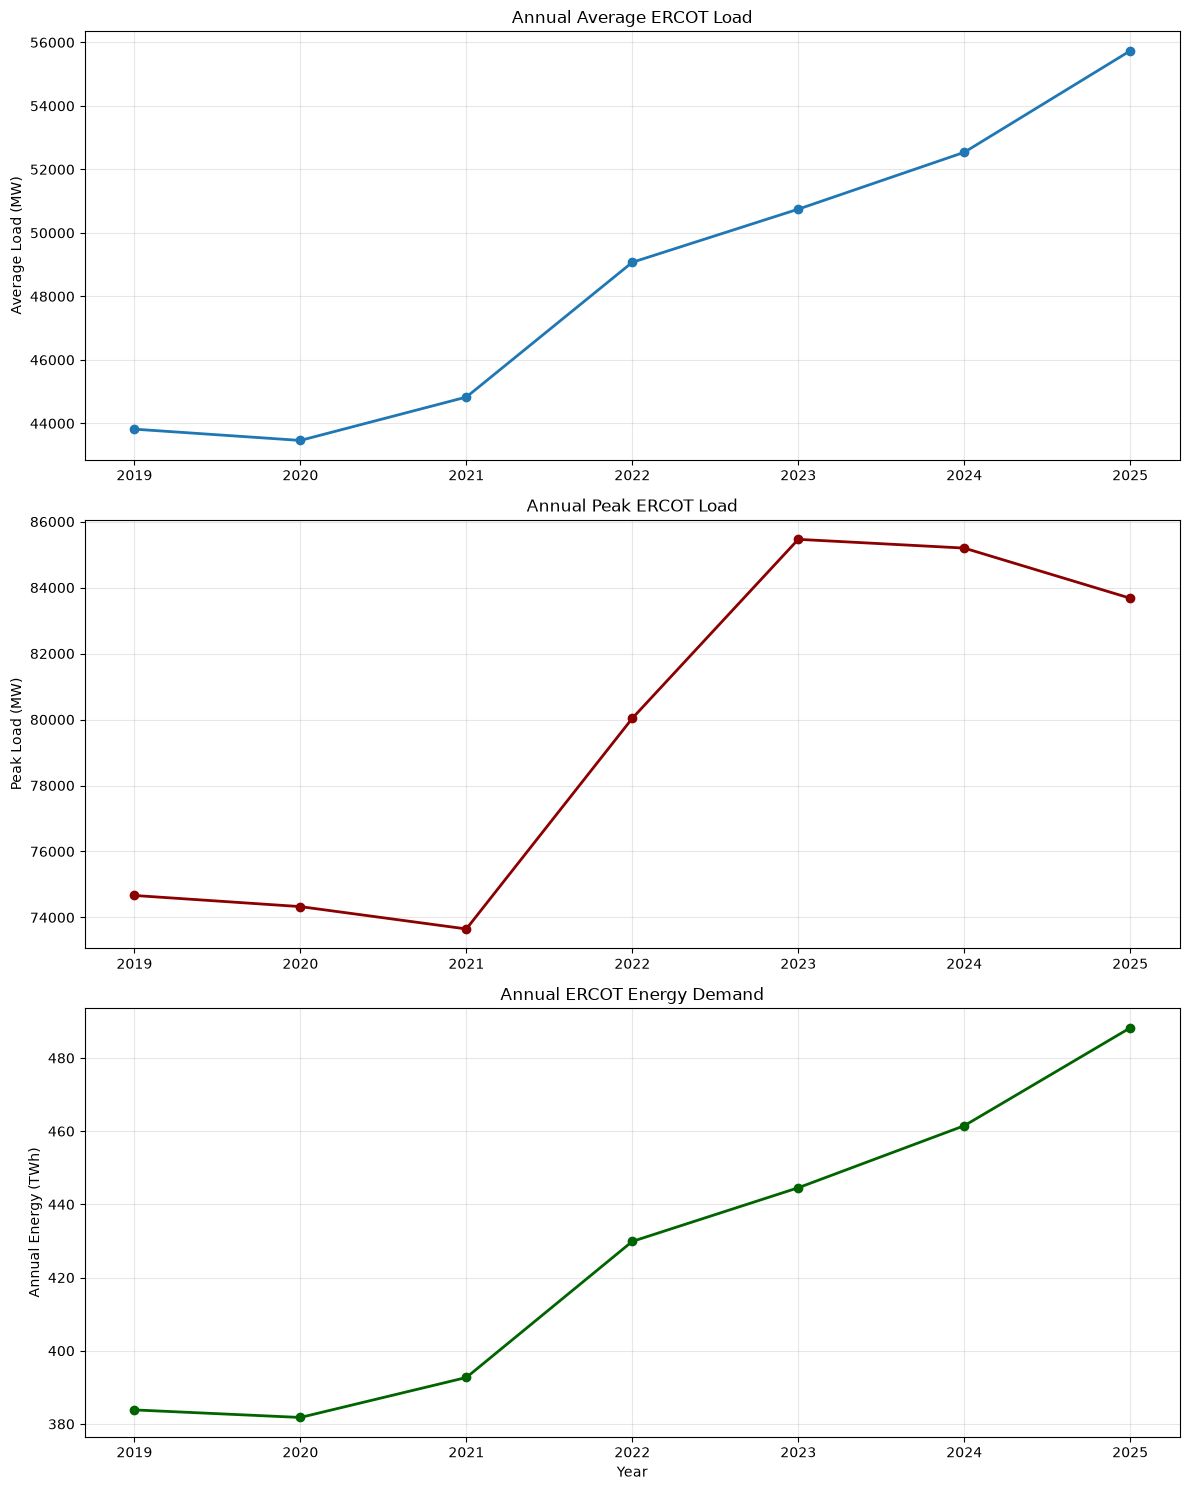

In [35]:
# Plot the annual mean load, annual peak load, and annual electricity consumption trends.
# Figures are exported to `report/figures` as high-resolution PNG files.

import matplotlib.pyplot as plt

figure, axes = plt.subplots(
    nrows=3,
    ncols=1,
    figsize=(12, 15),
)

axes[0].plot(
    annual_overview["year"],
    annual_overview["average_load_mw"],
    marker="o",
    linewidth=2,
)

axes[0].set_title("Annual Average ERCOT Load")

axes[0].set_ylabel("Average Load (MW)")

axes[0].grid(alpha=0.3)

axes[1].plot(
    annual_overview["year"],
    annual_overview["peak_load_mw"],
    marker="o",
    color="darkred",
    linewidth=2,
)

axes[1].set_title("Annual Peak ERCOT Load")

axes[1].set_ylabel("Peak Load (MW)")

axes[1].grid(alpha=0.3)

axes[2].plot(
    annual_overview["year"],
    annual_overview["annual_energy_twh"],
    marker="o",
    color="darkgreen",
    linewidth=2,
)

axes[2].set_title("Annual ERCOT Energy Demand")

axes[2].set_xlabel("Year")

axes[2].set_ylabel("Annual Energy (TWh)")

axes[2].grid(alpha=0.3)

plt.tight_layout()
# save result
figures_dir = (
    project_root
    / "report"
    / "figures"
)

figures_dir.mkdir(
    parents=True,
    exist_ok=True,
)

annual_trends_figure_path = (
    figures_dir
    / "annual_ercot_load_trends_2019_2025.png"
)

figure.savefig(
    annual_trends_figure_path,
    dpi=300,
    bbox_inches="tight",
)

print(
    f"Figure saved to: {annual_trends_figure_path.relative_to(project_root).as_posix()}"
)

plt.show()
plt.show()


### Interpretation of Annual Trends

- Average ERCOT load and annual electricity use have a clear upward trend. Both declined slightly in 2020, recovered in 2021, and increased substantially beginning in 2022.
- Average hourly load rose from approximately 43.8 GW in 2019 to 55.7 GW in 2025, while annual electricity consumption rose from approximately 383.8 TWh to 488.2 TWh.
- Annual peak load was highest in the observed period in 2023 (approximately 85.5 GW), followed by modest declines in 2024 and 2025 despite continued growth in average load.
- Rising average load alongside moderately lower annual peaks suggests that recent demand growth is distributed more broadly across hours, rather than confined to isolated extremes.
- These charts establish **descriptive patterns, not causation**. Attribution would require weather and other explanatory variables.


In [39]:
# Summarize monthly electricity demand and write the monthly statistics to CSV.
# Monthly means are reported independently for each year–month pair.

# part4 ## 4. Monthly and Seasonal Load Patterns
monthly_by_year = (
    eda_data
    .groupby(
        ["year", "month"],
        as_index=False,
    )
    .agg(
        observation_count=(
            "ERCOT",
            "count",
        ),
        average_load_mw=(
            "ERCOT",
            "mean",
        ),
        median_load_mw=(
            "ERCOT",
            "median",
        ),
        peak_load_mw=(
            "ERCOT",
            "max",
        ),
        monthly_energy_mwh=(
            "ERCOT",
            "sum",
        ),
    )
)

month_name_mapping = {
    1: "Jan",
    2: "Feb",
    3: "Mar",
    4: "Apr",
    5: "May",
    6: "Jun",
    7: "Jul",
    8: "Aug",
    9: "Sep",
    10: "Oct",
    11: "Nov",
    12: "Dec",
}

monthly_by_year["month_name"] = (
    monthly_by_year["month"]
    .map(month_name_mapping)
)

monthly_by_year["monthly_energy_twh"] = (
    monthly_by_year["monthly_energy_mwh"]
    / 1_000_000
)

monthly_by_year = monthly_by_year.drop(
    columns=["monthly_energy_mwh"]
)

monthly_by_year = monthly_by_year.sort_values(
    ["year", "month"]
).reset_index(
    drop=True
)

print(
    "Monthly summary shape:",
    monthly_by_year.shape,
)

display(
    monthly_by_year.head(12)
)
monthly_summary_path = (
    tables_dir
    / "monthly_load_summary_2019_2025.csv"
)

monthly_by_year.to_csv(
    monthly_summary_path,
    index=False,
)

print(
    f"Monthly summary saved to: {monthly_summary_path.relative_to(project_root).as_posix()}"
)


Monthly summary shape: (84, 8)


,year,month,observation_count,average_load_mw,median_load_mw,peak_load_mw,month_name,monthly_energy_twh
0,2019,1,744,"40,076.166","39,633.382","54,669.513",Jan,29.817
1,2019,2,672,"38,818.385","38,354.066","53,731.264",Feb,26.086
2,2019,3,743,"37,388.910","36,873.037","60,652.150",Mar,27.780
3,2019,4,720,"37,211.811","36,964.409","51,635.447",Apr,26.793
4,2019,5,744,"43,052.093","42,503.265","60,816.501",May,32.031
5,2019,6,720,"48,831.172","48,778.972","68,124.467",Jun,35.158
6,2019,7,744,"52,728.989","52,753.954","70,854.821",Jul,39.230
7,2019,8,744,"56,255.042","55,630.546","74,665.579",Aug,41.854
8,2019,9,720,"51,794.904","51,234.784","68,958.595",Sep,37.292
9,2019,10,744,"41,239.158","39,317.069","65,197.488",Oct,30.682


Monthly summary saved to: report/tables/monthly_load_summary_2019_2025.csv


In [38]:
# Create report output directories if they do not already exist.

tables_dir = project_root / "report" / "tables"

tables_dir.mkdir(
    parents=True,
    exist_ok=True,
)

figures_dir = project_root / "report" / "figures"

figures_dir.mkdir(
    parents=True,
    exist_ok=True,
)

print("Tables directory:", tables_dir.relative_to(project_root).as_posix())
print("Figures directory:", figures_dir.relative_to(project_root).as_posix())


Tables directory: report/tables
Figures directory: report/figures


In [40]:
# Aggregate annual-by-season load statistics and export the seasonal summary.

seasonal_by_year = (
    eda_data
    .groupby(
        ["year", "season"],
        as_index=False,
    )
    .agg(
        observation_count=(
            "ERCOT",
            "count",
        ),
        average_load_mw=(
            "ERCOT",
            "mean",
        ),
        peak_load_mw=(
            "ERCOT",
            "max",
        ),
        load_std_mw=(
            "ERCOT",
            "std",
        ),
        seasonal_energy_mwh=(
            "ERCOT",
            "sum",
        ),
    )
)

season_order_mapping = {
    "Winter": 1,
    "Spring": 2,
    "Summer": 3,
    "Fall": 4,
}

seasonal_by_year["season_order"] = (
    seasonal_by_year["season"]
    .map(season_order_mapping)
)

seasonal_by_year["seasonal_energy_twh"] = (
    seasonal_by_year["seasonal_energy_mwh"]
    / 1_000_000
)

seasonal_by_year = seasonal_by_year.drop(
    columns=["seasonal_energy_mwh"]
)

seasonal_by_year = seasonal_by_year.sort_values(
    ["year", "season_order"]
).reset_index(
    drop=True
)

print(
    "Seasonal summary shape:",
    seasonal_by_year.shape,
)

display(
    seasonal_by_year.head(8)
)
seasonal_summary_path = (
    tables_dir
    / "seasonal_load_summary_2019_2025.csv"
)

seasonal_by_year.to_csv(
    seasonal_summary_path,
    index=False,
)

print(
    f"Seasonal summary saved to: {seasonal_summary_path.relative_to(project_root).as_posix()}"
)


Seasonal summary shape: (28, 8)


,year,season,observation_count,average_load_mw,peak_load_mw,load_std_mw,season_order,seasonal_energy_twh
0,2019,Winter,2160,"39,451.877","56,066.142","4,803.076",1,85.216
1,2019,Spring,2207,"39,240.245","60,816.501","6,950.734",2,86.603
2,2019,Summer,2208,"52,646.088","74,665.579","9,960.816",3,116.243
3,2019,Fall,2185,"43,836.710","68,958.595","9,589.678",4,95.783
4,2020,Winter,2184,"39,986.891","56,116.336","4,439.315",1,87.331
5,2020,Spring,2207,"39,163.976","64,396.100","6,708.916",2,86.435
6,2020,Summer,2208,"52,832.433","74,327.837","10,220.606",3,116.654
7,2020,Fall,2185,"41,812.046","64,794.854","7,491.015",4,91.359


Seasonal summary saved to: report/tables/seasonal_load_summary_2019_2025.csv


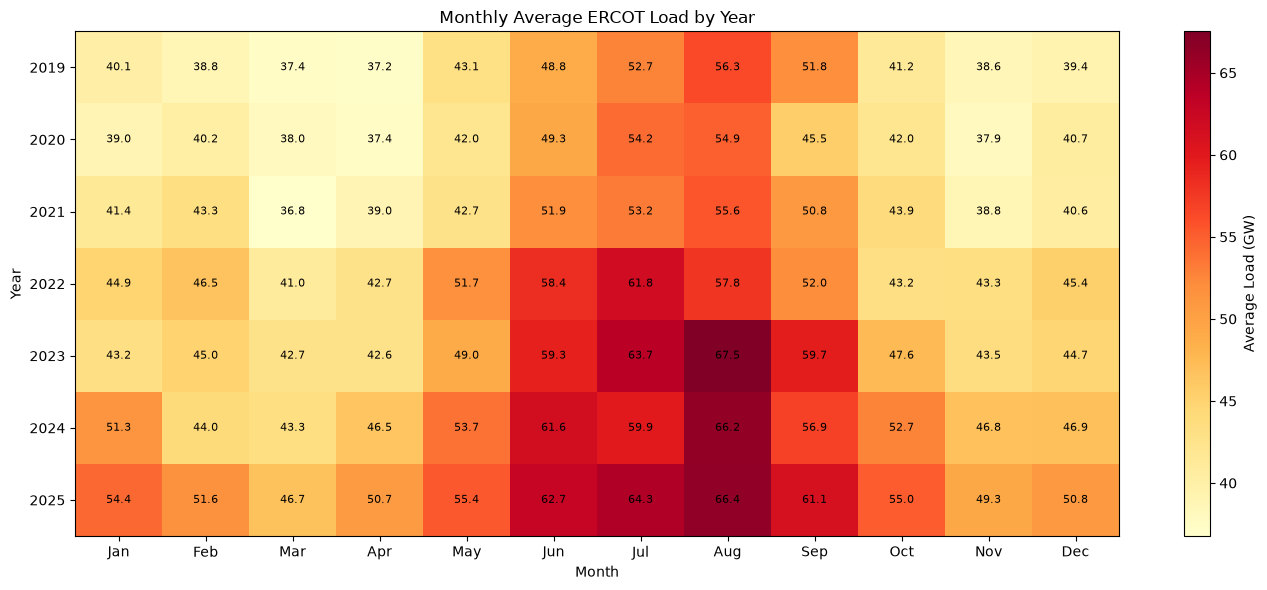

Monthly heatmap saved to: report/figures/monthly_average_load_heatmap_2019_2025.png


In [43]:
# Visualize monthly mean load (year × month) as a heatmap.

monthly_average_matrix = monthly_by_year.pivot(
    index="year",
    columns="month",
    values="average_load_mw",
)

monthly_average_matrix_gw = (
    monthly_average_matrix
    / 1_000
)

monthly_figure, monthly_axis = plt.subplots(
    figsize=(14, 6)
)

monthly_image = monthly_axis.imshow(
    monthly_average_matrix_gw,
    cmap="YlOrRd",
    aspect="auto",
)

monthly_axis.set_xticks(
    range(12)
)

monthly_axis.set_xticklabels(
    [month_name_mapping[month] for month in range(1, 13)]
)

monthly_axis.set_yticks(
    range(len(monthly_average_matrix_gw.index))
)

monthly_axis.set_yticklabels(
    monthly_average_matrix_gw.index
)

monthly_axis.set_title(
    "Monthly Average ERCOT Load by Year"
)

monthly_axis.set_xlabel("Month")

monthly_axis.set_ylabel("Year")

for row_position, year in enumerate(
    monthly_average_matrix_gw.index
):
    for column_position, month in enumerate(
        range(1, 13)
    ):
        cell_value = monthly_average_matrix_gw.loc[
            year,
            month,
        ]

        monthly_axis.text(
            column_position,
            row_position,
            f"{cell_value:.1f}",
            ha="center",
            va="center",
            fontsize=8,
            color="black",
        )

monthly_colorbar = monthly_figure.colorbar(
    monthly_image,
    ax=monthly_axis,
)

monthly_colorbar.set_label(
    "Average Load (GW)"
)

monthly_figure.tight_layout()

monthly_heatmap_path = (
    figures_dir
    / "monthly_average_load_heatmap_2019_2025.png"
)

monthly_figure.savefig(
    monthly_heatmap_path,
    dpi=300,
    bbox_inches="tight",
)

plt.show()

print(
    f"Monthly heatmap saved to: {monthly_heatmap_path.relative_to(project_root).as_posix()}"
)


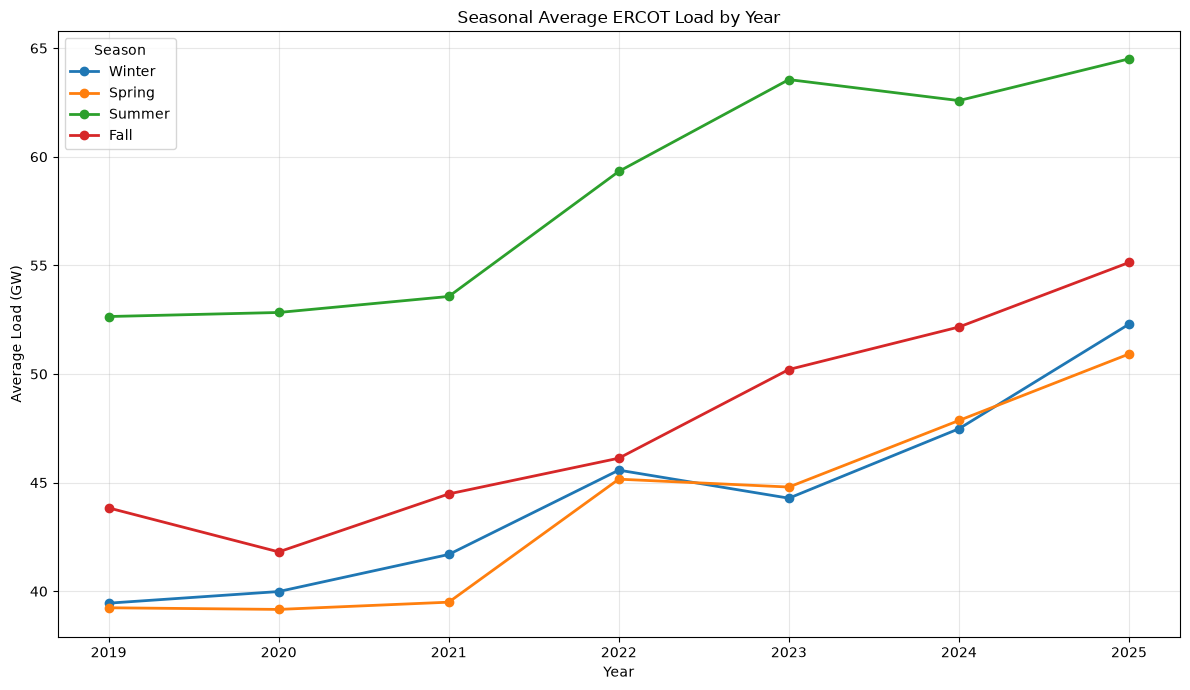

Seasonal figure saved to: report/figures/seasonal_average_load_trends_2019_2025.png


In [44]:
# Plot and save annual average load trajectories separately for each season.

seasonal_figure, seasonal_axis = plt.subplots(
    figsize=(12, 7)
)

for season in [
    "Winter",
    "Spring",
    "Summer",
    "Fall",
]:
    season_data = seasonal_by_year.loc[
        seasonal_by_year["season"] == season
    ]

    seasonal_axis.plot(
        season_data["year"],
        season_data["average_load_mw"] / 1_000,
        marker="o",
        linewidth=2,
        label=season,
    )

seasonal_axis.set_title(
    "Seasonal Average ERCOT Load by Year"
)

seasonal_axis.set_xlabel("Year")

seasonal_axis.set_ylabel("Average Load (GW)")

seasonal_axis.grid(
    alpha=0.3
)

seasonal_axis.legend(
    title="Season"
)

seasonal_figure.tight_layout()

seasonal_figure_path = (
    figures_dir
    / "seasonal_average_load_trends_2019_2025.png"
)

seasonal_figure.savefig(
    seasonal_figure_path,
    dpi=300,
    bbox_inches="tight",
)

plt.show()

print(
    f"Seasonal figure saved to: {seasonal_figure_path.relative_to(project_root).as_posix()}"
)


### Monthly and Seasonal Findings

- ERCOT demand exhibits strong summer seasonality. **June–September** have consistently high monthly averages; **August** is frequently the highest-demand month.
- Load growth in 2022 affected multiple months, particularly **May–July**, rather than being driven by a single isolated event.
- Summer 2023 was the highest-demand summer in the analyzed period. The August monthly average was approximately **67.5 GW**, the highest monthly mean in the dataset.
- Although summer remains the highest-load season, winter, spring, and fall also experienced substantial increases. Winter demand growth matters for reliability planning during extreme cold conditions.
- These differences are **descriptive rather than causal**; temperature and extreme-weather data are needed to evaluate weather-related contributions.


## 5–7. Weekly, Intraday, and Seasonal-Hourly Load Profiles

Calendar effects may confound weather–demand relationships. At the same temperature, weekday and weekend consumption can differ, as can overnight and afternoon load. The following analyses compare:

1. **Day of week / weekday versus weekend:** Do working days differ from weekends?
2. **Hour of day:** At what times are average demand minima and maxima observed?
3. **Season × hour:** How do the 24-hour profiles differ between summer, winter, and other seasons?

These patterns inform the calendar controls used later in the weather analysis.


In [47]:
# Compare average electricity demand across weekdays and weekends.
# Weekday and weekend comparisons are descriptive and do not control for weather.

# 5.1## 5.1 Day-of-Week and Weekend Patterns
day_of_week_summary = (
    eda_data
    .groupby(
        ["day_of_week", "day_name"],
        as_index=False,
    )
    .agg(
        observation_count=(
            "ERCOT",
            "count",
        ),
        average_load_mw=(
            "ERCOT",
            "mean",
        ),
        median_load_mw=(
            "ERCOT",
            "median",
        ),
        peak_load_mw=(
            "ERCOT",
            "max",
        ),
        load_std_mw=(
            "ERCOT",
            "std",
        ),
    )
    .sort_values("day_of_week")
    .reset_index(
        drop=True
    )
)

weekday_weekend_summary = (
    eda_data
    .groupby(
        "is_weekend",
        as_index=False,
    )
    .agg(
        observation_count=(
            "ERCOT",
            "count",
        ),
        average_load_mw=(
            "ERCOT",
            "mean",
        ),
        median_load_mw=(
            "ERCOT",
            "median",
        ),
        peak_load_mw=(
            "ERCOT",
            "max",
        ),
    )
)

weekday_weekend_summary["day_type"] = (
    weekday_weekend_summary["is_weekend"]
    .map({
        False: "Weekday",
        True: "Weekend",
    })
)

day_of_week_summary_path = (
    tables_dir
    / "day_of_week_load_summary_2019_2025.csv"
)

day_of_week_summary.to_csv(
    day_of_week_summary_path,
    index=False,
)

weekday_weekend_summary_path = (
    tables_dir
    / "weekday_weekend_load_summary_2019_2025.csv"
)

weekday_weekend_summary.to_csv(
    weekday_weekend_summary_path,
    index=False,
)

display(day_of_week_summary)

display(weekday_weekend_summary)

print("Day-of-week table saved to:", day_of_week_summary_path.relative_to(project_root).as_posix())
print("Weekday/weekend table saved to:", weekday_weekend_summary_path.relative_to(project_root).as_posix())


,day_of_week,day_name,observation_count,average_load_mw,median_load_mw,peak_load_mw,load_std_mw
0,0,Monday,8760,"49,067.286","46,653.948","84,766.646","11,268.045"
1,1,Tuesday,8784,"49,171.120","46,692.872","85,198.850","11,053.480"
2,2,Wednesday,8784,"49,110.504","46,636.720","84,836.525","11,005.575"
3,3,Thursday,8760,"49,198.544","46,699.614","85,464.116","11,200.524"
4,4,Friday,8760,"49,086.940","46,696.691","85,037.849","11,166.068"
5,5,Saturday,8760,"47,479.346","44,983.274","84,653.972","10,978.056"
6,6,Sunday,8760,"47,083.201","44,606.624","84,951.756","11,110.184"


,is_weekend,observation_count,average_load_mw,median_load_mw,peak_load_mw,day_type
0,False,43848,"49,126.894","46,677.641","85,464.116",Weekday
1,True,17520,"47,281.273","44,791.280","84,951.756",Weekend


Day-of-week table saved to: report/tables/day_of_week_load_summary_2019_2025.csv
Weekday/weekend table saved to: report/tables/weekday_weekend_load_summary_2019_2025.csv


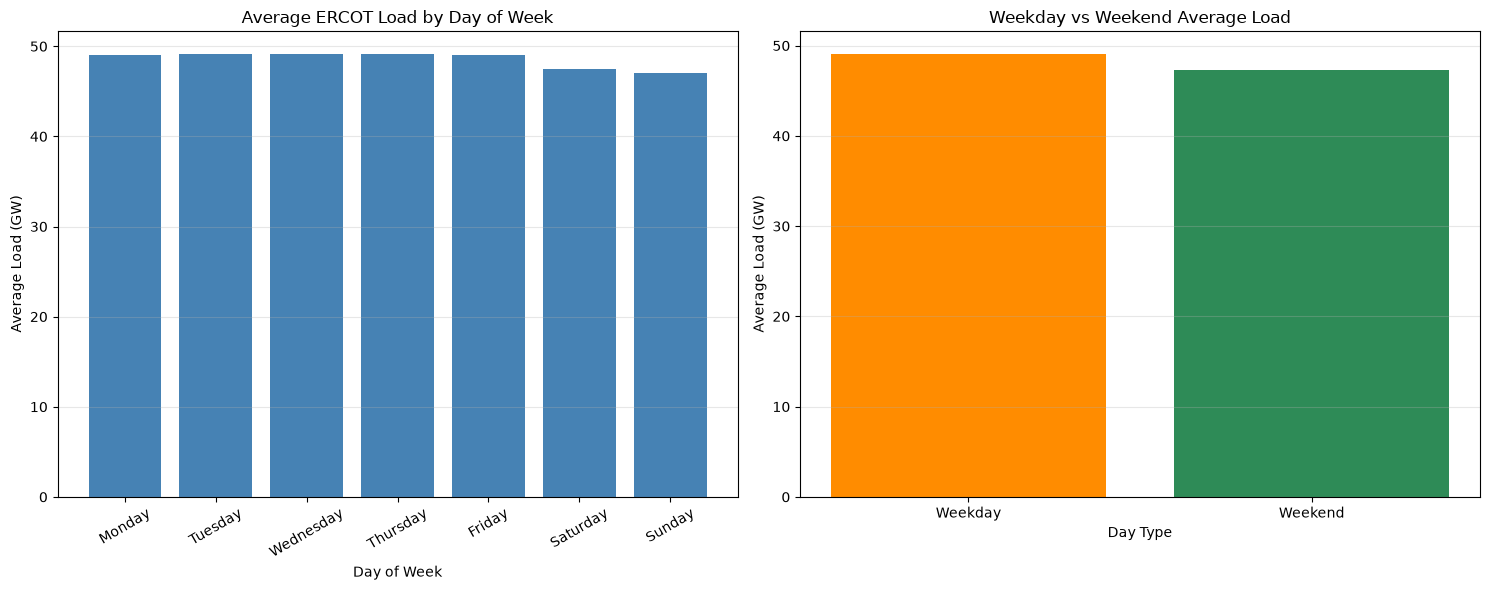

Day-pattern figure saved to: report/figures/day_of_week_and_weekend_patterns_2019_2025.png


In [48]:
# Visualize the differences in day-of-week and weekday/weekend demand patterns.

# plot
day_figure, day_axes = plt.subplots(
    nrows=1,
    ncols=2,
    figsize=(15, 6),
)

day_axes[0].bar(
    day_of_week_summary["day_name"],
    day_of_week_summary["average_load_mw"] / 1_000,
    color="steelblue",
)

day_axes[0].set_title("Average ERCOT Load by Day of Week")

day_axes[0].set_xlabel("Day of Week")

day_axes[0].set_ylabel("Average Load (GW)")

day_axes[0].tick_params(
    axis="x",
    rotation=30,
)

day_axes[0].grid(
    axis="y",
    alpha=0.3,
)

day_axes[1].bar(
    weekday_weekend_summary["day_type"],
    weekday_weekend_summary["average_load_mw"] / 1_000,
    color=["darkorange", "seagreen"],
)

day_axes[1].set_title("Weekday vs Weekend Average Load")

day_axes[1].set_xlabel("Day Type")

day_axes[1].set_ylabel("Average Load (GW)")

day_axes[1].grid(
    axis="y",
    alpha=0.3,
)

day_figure.tight_layout()

day_figure_path = (
    figures_dir
    / "day_of_week_and_weekend_patterns_2019_2025.png"
)

day_figure.savefig(
    day_figure_path,
    dpi=300,
    bbox_inches="tight",
)

plt.show()

print("Day-pattern figure saved to:", day_figure_path.relative_to(project_root).as_posix())


In [49]:
# Compute and export the typical 24-hour ERCOT load profile.

# 6## 6. Intraday Hourly Load Pattern
hourly_summary = (
    eda_data
    .groupby(
        "hour",
        as_index=False,
    )
    .agg(
        observation_count=(
            "ERCOT",
            "count",
        ),
        average_load_mw=(
            "ERCOT",
            "mean",
        ),
        median_load_mw=(
            "ERCOT",
            "median",
        ),
        peak_load_mw=(
            "ERCOT",
            "max",
        ),
        load_std_mw=(
            "ERCOT",
            "std",
        ),
    )
    .sort_values("hour")
    .reset_index(
        drop=True
    )
)

hourly_summary_path = (
    tables_dir
    / "hourly_load_summary_2019_2025.csv"
)

hourly_summary.to_csv(
    hourly_summary_path,
    index=False,
)

display(hourly_summary)

print("Hourly summary saved to:", hourly_summary_path.relative_to(project_root).as_posix())


,hour,observation_count,average_load_mw,median_load_mw,peak_load_mw,load_std_mw
0,0,2557,"43,785.945","42,734.137","72,156.452","8,244.370"
1,1,2564,"42,143.176","41,293.141","72,020.355","7,772.439"
2,2,2550,"41,099.990","40,352.245","72,288.239","7,402.825"
3,3,2557,"40,539.724","39,775.477","72,643.215","7,149.124"
4,4,2557,"40,667.343","39,918.004","74,019.459","6,999.492"
5,5,2557,"41,770.900","41,121.903","75,823.787","6,937.672"
6,6,2557,"43,636.284","43,112.169","79,211.854","6,970.047"
7,7,2557,"44,749.943","44,217.814","80,524.699","6,950.567"
8,8,2557,"45,947.900","45,511.215","79,228.485","6,967.383"
9,9,2557,"47,521.528","46,988.086","77,226.134","7,365.417"


Hourly summary saved to: report/tables/hourly_load_summary_2019_2025.csv


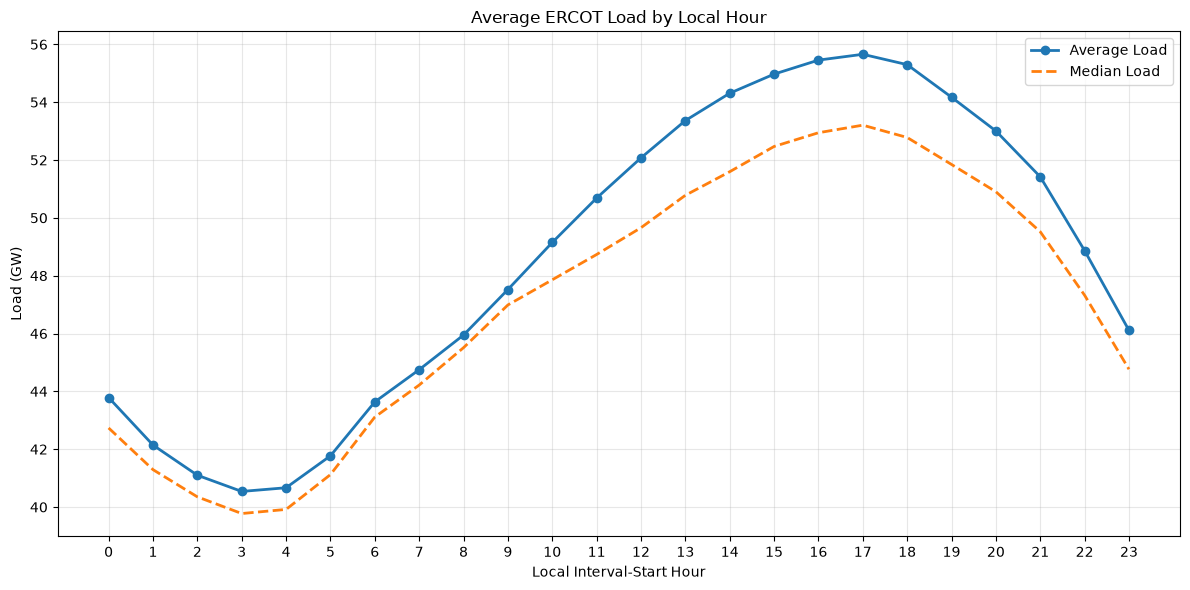

Hourly figure saved to: report/figures/intraday_hourly_load_pattern_2019_2025.png


In [50]:
# Plot the overall intraday average and median hourly demand.

hourly_figure, hourly_axis = plt.subplots(
    figsize=(12, 6)
)

hourly_axis.plot(
    hourly_summary["hour"],
    hourly_summary["average_load_mw"] / 1_000,
    marker="o",
    linewidth=2,
    label="Average Load",
)

hourly_axis.plot(
    hourly_summary["hour"],
    hourly_summary["median_load_mw"] / 1_000,
    linestyle="--",
    linewidth=2,
    label="Median Load",
)

hourly_axis.set_title("Average ERCOT Load by Local Hour")

hourly_axis.set_xlabel("Local Interval-Start Hour")

hourly_axis.set_ylabel("Load (GW)")

hourly_axis.set_xticks(
    range(24)
)

hourly_axis.grid(
    alpha=0.3
)

hourly_axis.legend()

hourly_figure.tight_layout()

hourly_figure_path = (
    figures_dir
    / "intraday_hourly_load_pattern_2019_2025.png"
)

hourly_figure.savefig(
    hourly_figure_path,
    dpi=300,
    bbox_inches="tight",
)

plt.show()

print("Hourly figure saved to:", hourly_figure_path.relative_to(project_root).as_posix())


In [51]:
# Aggregate the hour-of-day profile separately for each season.

# ## 7. Seasonal Intraday Load Profiles
seasonal_hourly_summary = (
    eda_data
    .groupby(
        ["season", "hour"],
        as_index=False,
    )
    .agg(
        observation_count=(
            "ERCOT",
            "count",
        ),
        average_load_mw=(
            "ERCOT",
            "mean",
        ),
        median_load_mw=(
            "ERCOT",
            "median",
        ),
        peak_load_mw=(
            "ERCOT",
            "max",
        ),
    )
)

seasonal_hourly_summary["season_order"] = (
    seasonal_hourly_summary["season"]
    .map(season_order_mapping)
)

seasonal_hourly_summary = seasonal_hourly_summary.sort_values(
    ["season_order", "hour"]
).reset_index(
    drop=True
)

seasonal_hourly_summary_path = (
    tables_dir
    / "seasonal_hourly_load_summary_2019_2025.csv"
)

seasonal_hourly_summary.to_csv(
    seasonal_hourly_summary_path,
    index=False,
)

display(
    seasonal_hourly_summary.head(12)
)

print(
    "Seasonal-hourly summary saved to:",
    seasonal_hourly_summary_path.relative_to(project_root).as_posix(),
)


,season,hour,observation_count,average_load_mw,median_load_mw,peak_load_mw,season_order
0,Winter,0,632,"41,044.824","39,716.320","72,156.452",1
1,Winter,1,632,"40,361.286","38,938.208","72,020.355",1
2,Winter,2,632,"40,098.537","38,831.553","72,288.239",1
3,Winter,3,632,"40,268.018","39,094.024","72,643.215",1
4,Winter,4,632,"41,091.497","39,915.387","74,019.459",1
5,Winter,5,632,"42,950.724","41,772.496","75,823.787",1
6,Winter,6,632,"45,732.003","44,739.459","79,211.854",1
7,Winter,7,632,"47,245.055","46,057.761","80,524.699",1
8,Winter,8,632,"47,364.009","46,103.356","79,228.485",1
9,Winter,9,632,"47,053.240","45,921.731","77,226.134",1


Seasonal-hourly summary saved to: report/tables/seasonal_hourly_load_summary_2019_2025.csv


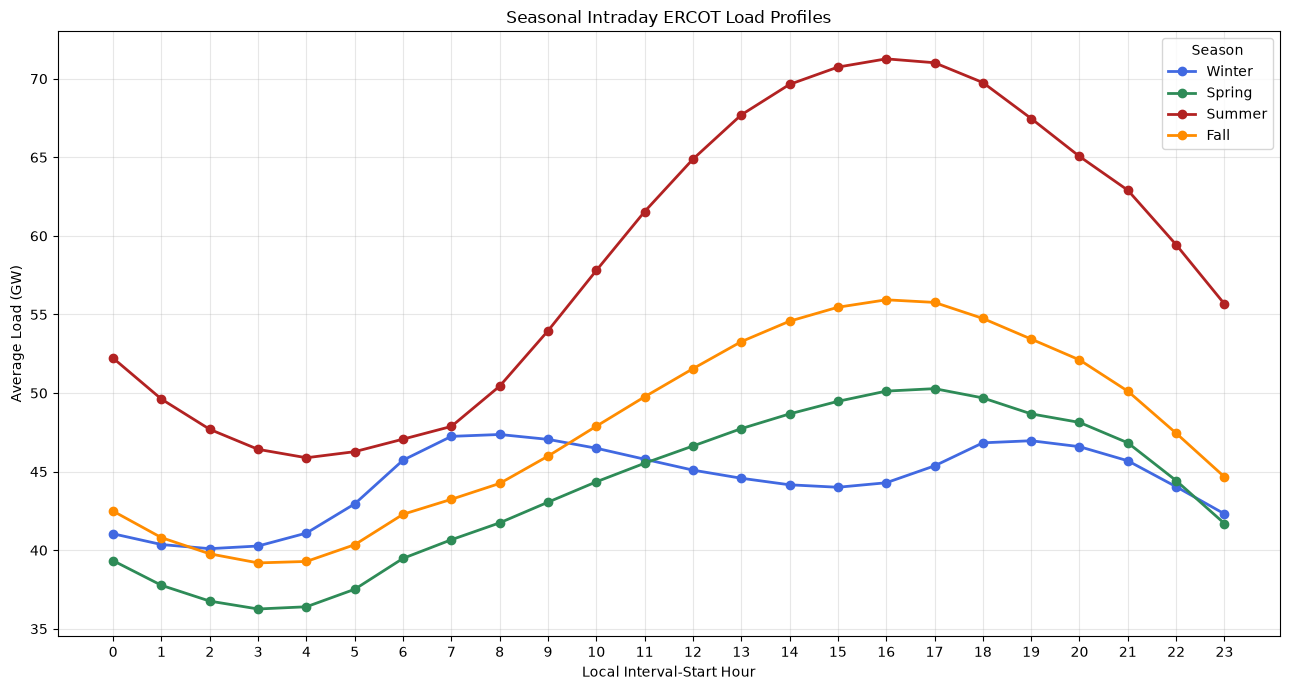

Seasonal-hourly figure saved to: report/figures/seasonal_intraday_load_profiles_2019_2025.png


In [52]:
# Plot and save seasonal intraday demand profiles.

season_colors = {
    "Winter": "royalblue",
    "Spring": "seagreen",
    "Summer": "firebrick",
    "Fall": "darkorange",
}

seasonal_hourly_figure, seasonal_hourly_axis = plt.subplots(
    figsize=(13, 7)
)

for season in [
    "Winter",
    "Spring",
    "Summer",
    "Fall",
]:
    current_season_data = seasonal_hourly_summary.loc[
        seasonal_hourly_summary["season"] == season
    ]

    seasonal_hourly_axis.plot(
        current_season_data["hour"],
        current_season_data["average_load_mw"] / 1_000,
        marker="o",
        linewidth=2,
        color=season_colors[season],
        label=season,
    )

seasonal_hourly_axis.set_title(
    "Seasonal Intraday ERCOT Load Profiles"
)

seasonal_hourly_axis.set_xlabel(
    "Local Interval-Start Hour"
)

seasonal_hourly_axis.set_ylabel(
    "Average Load (GW)"
)

seasonal_hourly_axis.set_xticks(
    range(24)
)

seasonal_hourly_axis.grid(
    alpha=0.3
)

seasonal_hourly_axis.legend(
    title="Season"
)

seasonal_hourly_figure.tight_layout()

seasonal_hourly_figure_path = (
    figures_dir
    / "seasonal_intraday_load_profiles_2019_2025.png"
)

seasonal_hourly_figure.savefig(
    seasonal_hourly_figure_path,
    dpi=300,
    bbox_inches="tight",
)

plt.show()

print(
    "Seasonal-hourly figure saved to:",
    seasonal_hourly_figure_path.relative_to(project_root).as_posix(),
)


### Weekly and Intraday Findings

- Average weekday load exceeds average weekend load. Monday–Friday are broadly similar, followed by lower Saturday demand and the lowest weekly demand on Sunday.
- The overall intraday demand profile reaches a minimum at approximately **03:00 local interval-start time**, rises through the morning and afternoon, and peaks around **17:00**.
- The difference between typical daily minimum and maximum load is approximately **15 GW**, indicating a substantial intraday ramping requirement.
- Summer has the highest and steepest intraday profile, reaching approximately **71 GW** during the late afternoon; this pattern is consistent with strong cooling-related demand.
- Winter has a different, approximately double-peaked profile, with elevated demand around **07:00–08:00** and again in the early evening.
- These findings reinforce the need to **control for weekday and hourly effects** when assessing weather sensitivity.


## 8. Peak and Sustained High-Load Events

Translate descriptive load patterns into demand-risk indicators useful for planning:

- **8.1 Sustained high-load events:** identify how high load rises, how many consecutive hours exceed a threshold, and when such events occur.
- **8.2 Regional load structure:** identify which ERCOT weather zones account for load growth and coincident peaks (developed further in Section 9).

The fixed thresholds used here are the **P95** and **P99** percentiles of the full historical system-load series. These are descriptive thresholds, not prospective risk probabilities.


In [55]:
# Calculate fixed historical P95 and P99 load thresholds and the observed historical peak.
# The percentile thresholds are fixed across the full historical series.

## 8.1 Peak and Sustained High-Load Events

p95_load_mw = (
    eda_data["ERCOT"]
    .quantile(0.95)
)

p99_load_mw = (
    eda_data["ERCOT"]
    .quantile(0.99)
)

historical_peak_mw = (
    eda_data["ERCOT"]
    .max()
)

peak_thresholds = pd.Series({
    "p95_load_mw": p95_load_mw,
    "p99_load_mw": p99_load_mw,
    "historical_peak_mw": historical_peak_mw,
}, name="value_mw")

peak_thresholds_path = (
    tables_dir
    / "peak_load_thresholds_2019_2025.csv"
)

peak_thresholds.to_csv(
    peak_thresholds_path,
    index=True,
)

display(
    peak_thresholds.to_frame()
)

print(
    f"Peak thresholds saved to: {peak_thresholds_path.relative_to(project_root).as_posix()}"
)


,value_mw
p95_load_mw,"71,057.743"
p99_load_mw,"78,955.800"
historical_peak_mw,"85,464.116"


Peak thresholds saved to: report/tables/peak_load_thresholds_2019_2025.csv


In [56]:
# Identify contiguous periods at or above the historical P95 threshold on the UTC timeline.
# Episode boundaries follow UTC time continuity to avoid artifacts from repeated or missing local DST clock labels.

peak_event_data = (
    eda_data
    .sort_values("HourEnding_utc")
    .reset_index(
        drop=True
    )
    .copy()
)

peak_event_data["high_load_flag"] = (
    peak_event_data["ERCOT"]
    >= p95_load_mw
)

peak_event_data["utc_difference"] = (
    peak_event_data["HourEnding_utc"]
    .diff()
)

previous_hour_was_high = (
    peak_event_data["high_load_flag"]
    .shift(
        fill_value=False
    )
)

current_hour_is_continuous = (
    peak_event_data["utc_difference"]
    == pd.Timedelta(hours=1)
)

peak_event_data["new_high_load_event"] = (
    peak_event_data["high_load_flag"]
    & (
        (~previous_hour_was_high)
        | (~current_hour_is_continuous)
    )
)

peak_event_data["high_load_event_id"] = (
    peak_event_data["new_high_load_event"]
    .cumsum()
    .where(
        peak_event_data["high_load_flag"]
    )
)

high_load_hours = (
    peak_event_data.loc[
        peak_event_data["high_load_flag"]
    ]
    .copy()
)

high_load_events = (
    high_load_hours
    .groupby(
        "high_load_event_id",
        as_index=False,
    )
    .agg(
        year=(
            "year",
            "first",
        ),
        season=(
            "season",
            "first",
        ),
        event_start_local=(
            "interval_start_local",
            "min",
        ),
        last_interval_start_local=(
            "interval_start_local",
            "max",
        ),
        event_end_utc=(
            "HourEnding_utc",
            "max",
        ),
        duration_hours=(
            "ERCOT",
            "size",
        ),
        average_load_mw=(
            "ERCOT",
            "mean",
        ),
        peak_load_mw=(
            "ERCOT",
            "max",
        ),
    )
)

high_load_events["event_end_local"] = (
    high_load_events["last_interval_start_local"]
    + pd.Timedelta(hours=1)
)

high_load_events = high_load_events.drop(
    columns=["last_interval_start_local"]
)

high_load_events = high_load_events.sort_values(
    ["duration_hours", "peak_load_mw"],
    ascending=[False, False],
).reset_index(
    drop=True
)

high_load_events_path = (
    tables_dir
    / "sustained_high_load_events_p95_2019_2025.csv"
)

high_load_events.to_csv(
    high_load_events_path,
    index=False,
)

display(
    high_load_events.head(20)
)

print(
    f"High-load events saved to: {high_load_events_path.relative_to(project_root).as_posix()}"
)


,high_load_event_id,year,season,event_start_local,event_end_utc,duration_hours,average_load_mw,peak_load_mw,event_end_local
0,328.000,2025,Winter,2025-02-19 06:00:00,2025-02-20 18:00:00+00:00,30,"75,018.687","80,524.699",2025-02-20 12:00:00
1,229.000,2024,Winter,2024-01-15 16:00:00,2024-01-16 18:00:00+00:00,20,"74,587.733","78,313.708",2024-01-16 12:00:00
2,181.000,2023,Summer,2023-08-10 11:00:00,2023-08-11 04:00:00+00:00,12,"80,649.211","85,464.116",2023-08-10 23:00:00
3,295.000,2024,Summer,2024-08-20 11:00:00,2024-08-21 04:00:00+00:00,12,"80,044.341","85,198.850",2024-08-20 23:00:00
4,182.000,2023,Summer,2023-08-11 11:00:00,2023-08-12 04:00:00+00:00,12,"80,016.011","85,037.849",2023-08-11 23:00:00
5,297.000,2024,Summer,2024-08-22 11:00:00,2024-08-23 04:00:00+00:00,12,"80,279.691","84,916.798",2024-08-22 23:00:00
6,296.000,2024,Summer,2024-08-21 11:00:00,2024-08-22 04:00:00+00:00,12,"79,653.721","84,836.525",2024-08-21 23:00:00
7,294.000,2024,Summer,2024-08-19 11:00:00,2024-08-20 04:00:00+00:00,12,"80,027.165","84,766.646",2024-08-19 23:00:00
8,183.000,2023,Summer,2023-08-12 11:00:00,2023-08-13 04:00:00+00:00,12,"78,963.389","84,479.238",2023-08-12 23:00:00
9,178.000,2023,Summer,2023-08-07 11:00:00,2023-08-08 04:00:00+00:00,12,"79,415.720","83,752.153",2023-08-07 23:00:00


High-load events saved to: report/tables/sustained_high_load_events_p95_2019_2025.csv


In [57]:
# Summarize high-load episode counts, durations, and exposure by year.

annual_high_load_summary = (
    high_load_events
    .groupby(
        "year",
        as_index=False,
    )
    .agg(
        event_count=(
            "high_load_event_id",
            "count",
        ),
        total_high_load_hours=(
            "duration_hours",
            "sum",
        ),
        longest_event_hours=(
            "duration_hours",
            "max",
        ),
        average_event_duration_hours=(
            "duration_hours",
            "mean",
        ),
        highest_event_peak_mw=(
            "peak_load_mw",
            "max",
        ),
    )
)

annual_high_load_summary_path = (
    tables_dir
    / "annual_high_load_event_summary_2019_2025.csv"
)

annual_high_load_summary.to_csv(
    annual_high_load_summary_path,
    index=False,
)

display(annual_high_load_summary)

print(
    "Annual high-load summary saved to:",
    annual_high_load_summary_path.relative_to(project_root).as_posix(),
)


,year,event_count,total_high_load_hours,longest_event_hours,average_event_duration_hours,highest_event_peak_mw
0,2019,18,56,6,3.111,"74,665.579"
1,2020,16,68,6,4.250,"74,327.837"
2,2021,23,76,5,3.304,"73,650.573"
3,2022,66,411,10,6.227,"80,037.836"
4,2023,104,802,12,7.712,"85,464.116"
5,2024,95,677,20,7.126,"85,198.850"
6,2025,131,979,30,7.473,"83,679.002"


Annual high-load summary saved to: report/tables/annual_high_load_event_summary_2019_2025.csv


### Peak and Sustained High-Load Findings

- The historical system-wide **P95** and **P99** hourly-load thresholds are approximately **71.06 GW** and **78.96 GW**, respectively; the observed historical maximum is approximately **85.46 GW**.
- High-demand conditions became much more common after 2021. Annual hours at or above the fixed historical P95 threshold increased from **56 hours in 2019** to **979 hours in 2025**.
- Summer high-load episodes produced the highest instantaneous peaks and often persisted for approximately **11–12 consecutive hours** during afternoons and evenings.
- The longest detected sustained event occurred during **winter 2025** and lasted **30 consecutive hours**; another winter event in 2024 lasted **20 hours**.
- These observations suggest two distinct planning challenges: very high summer peaks and long-duration winter stress. Short-duration storage can help mitigate an instantaneous peak but cannot independently cover the complete duration of the longest detected events.

*The event definition uses historical load-percentile thresholds and contiguous hourly UTC observations; these findings are descriptive, not estimates of future event probabilities.*


## 9. Regional Load Structure

Evaluate how ERCOT's eight weather zones contribute to total electricity demand, historical growth, and the **coincident system peak**. Zone-level analysis excludes records flagged for material disagreement between the reported system total and the sum of zone loads.


### Regional Analysis Plan

1. Check that all eight weather-zone columns are present.
2. Exclude the **48 flagged records** where regional load sums do not agree with the reported ERCOT system load.
3. Calculate annual regional mean load, regional peaks, and average-load shares.
4. Estimate regional absolute and relative growth from **2019 to 2025**, including contributions to system-level growth.
5. Visualize annual regional trends and 2025 regional shares.
6. Measure coincident regional contributions at the **system** peak and examine interregional load correlations.


In [60]:
# Validate eight zone columns and exclude rows flagged for inconsistent regional sums.
# The original dataset remains unchanged; only the regional analysis copy excludes flagged rows.

# 9.1
zone_columns = [
    "COAST",
    "EAST",
    "FWEST",
    "NORTH",
    "NCENT",
    "SOUTH",
    "SCENT",
    "WEST",
]

missing_zone_columns = (
    set(zone_columns)
    - set(eda_data.columns)
)

if missing_zone_columns:
    raise ValueError(
        f"Missing required weather-zone columns: "
        f"{sorted(missing_zone_columns)}"
    )

regional_valid_data = (
    eda_data.loc[
        ~eda_data["zone_total_mismatch_flag"]
    ]
    .copy()
)

excluded_regional_rows = (
    len(eda_data) - len(regional_valid_data)
)

regional_data_check = pd.Series({
    "original_row_count": len(eda_data),
    "regional_valid_row_count": len(regional_valid_data),
    "excluded_mismatch_rows": excluded_regional_rows,
    "zone_column_count": len(zone_columns),
}, name="value")

regional_data_check


original_row_count          61368
regional_valid_row_count    61320
excluded_mismatch_rows         48
zone_column_count               8
Name: value, dtype: int64

In [61]:
# Compute annual regional average and peak loads and save the zone summaries.

annual_zone_average_wide = (
    regional_valid_data
    .groupby(
        "year"
    )
    [zone_columns]
    .mean()
    .reset_index()
)

annual_zone_average = annual_zone_average_wide.melt(
    id_vars="year",
    var_name="zone",
    value_name="average_load_mw",
)

annual_zone_peak_wide = (
    regional_valid_data
    .groupby(
        "year"
    )
    [zone_columns]
    .max()
    .reset_index()
)

annual_zone_peak = annual_zone_peak_wide.melt(
    id_vars="year",
    var_name="zone",
    value_name="peak_load_mw",
)

annual_zone_summary = annual_zone_average.merge(
    annual_zone_peak,
    on=["year", "zone"],
    validate="one_to_one",
)

annual_zone_summary = annual_zone_summary.sort_values(
    ["year", "zone"]
).reset_index(
    drop=True
)

annual_zone_summary_path = (
    tables_dir
    / "annual_zone_load_summary_2019_2025.csv"
)

annual_zone_summary.to_csv(
    annual_zone_summary_path,
    index=False,
)

display(
    annual_zone_summary.head(16)
)

print(
    f"Annual zone summary saved to: {annual_zone_summary_path.relative_to(project_root).as_posix()}"
)


,year,zone,average_load_mw,peak_load_mw
0,2019,COAST,"12,354.095","21,256.115"
1,2019,EAST,"1,485.167","2,554.015"
2,2019,FWEST,"3,435.597","4,307.553"
3,2019,NCENT,"13,819.154","25,493.791"
4,2019,NORTH,854.126,"1,476.330"
5,2019,SCENT,"6,970.015","12,784.858"
6,2019,SOUTH,"3,607.939","6,039.713"
7,2019,WEST,"1,291.835","2,117.399"
8,2020,COAST,"12,515.201","20,904.859"
9,2020,EAST,"1,565.558","2,871.334"


Annual zone summary saved to: report/tables/annual_zone_load_summary_2019_2025.csv


In [63]:
# Calculate regional shares of average annual system load and check that shares total approximately 100%.
# Regional shares use matched, quality-screened observations for the zone and system denominator.

annual_ercot_average_valid = (
    regional_valid_data
    .groupby(
        "year",
        as_index=False,
    )
    .agg(
        ercot_average_load_mw=(
            "ERCOT",
            "mean",
        )
    )
)

annual_zone_structure = annual_zone_summary.merge(
    annual_ercot_average_valid,
    on="year",
    validate="many_to_one",
)

annual_zone_structure["average_load_share_pct"] = (
    annual_zone_structure["average_load_mw"]
    / annual_zone_structure["ercot_average_load_mw"]
    * 100
)

annual_zone_structure = annual_zone_structure.sort_values(
    ["year", "average_load_share_pct"],
    ascending=[True, False],
).reset_index(
    drop=True
)

annual_share_check = (
    annual_zone_structure
    .groupby(
        "year",
        as_index=False,
    )
    .agg(
        total_zone_share_pct=(
            "average_load_share_pct",
            "sum",
        )
    )
)

annual_zone_structure_path = (
    tables_dir
    / "annual_zone_load_structure_2019_2025.csv"
)

annual_zone_structure.to_csv(
    annual_zone_structure_path,
    index=False,
)

display(
    annual_zone_structure.loc[
        annual_zone_structure["year"] == 2025
    ]
)

display(annual_share_check)

print(
    f"Annual zone structure saved to: {annual_zone_structure_path.relative_to(project_root).as_posix()}"
)


,year,zone,average_load_mw,peak_load_mw,ercot_average_load_mw,average_load_share_pct
48,2025,NCENT,"15,306.618","27,531.756","55,734.427",27.463
49,2025,COAST,"14,745.712","23,006.703","55,734.427",26.457
50,2025,SCENT,"8,877.039","14,799.326","55,734.427",15.927
51,2025,FWEST,"7,478.222","8,773.080","55,734.427",13.418
52,2025,SOUTH,"4,434.740","7,155.622","55,734.427",7.957
53,2025,EAST,"1,817.982","3,696.722","55,734.427",3.262
54,2025,NORTH,"1,689.518","2,732.086","55,734.427",3.031
55,2025,WEST,"1,384.595","2,116.513","55,734.427",2.484


,year,total_zone_share_pct
0,2019,100.000
1,2020,100.000
2,2021,100.000
3,2022,100.000
4,2023,100.000
5,2024,100.000
6,2025,100.000


Annual zone structure saved to: report/tables/annual_zone_load_structure_2019_2025.csv


In [64]:
# Estimate each zone’s absolute growth, percentage growth, and contribution to total zonal load growth.

zone_growth_wide = annual_zone_average.pivot(
    index="zone",
    columns="year",
    values="average_load_mw",
)

zone_growth_summary = pd.DataFrame({
    "zone": zone_growth_wide.index,
    "average_load_2019_mw": zone_growth_wide[2019],
    "average_load_2025_mw": zone_growth_wide[2025],
}).reset_index(
    drop=True
)

zone_growth_summary["absolute_growth_mw"] = (
    zone_growth_summary["average_load_2025_mw"]
    - zone_growth_summary["average_load_2019_mw"]
)

zone_growth_summary["growth_pct"] = (
    zone_growth_summary["absolute_growth_mw"]
    / zone_growth_summary["average_load_2019_mw"]
    * 100
)

total_zone_growth_mw = (
    zone_growth_summary["absolute_growth_mw"]
    .sum()
)

zone_growth_summary["growth_contribution_pct"] = (
    zone_growth_summary["absolute_growth_mw"]
    / total_zone_growth_mw
    * 100
)

zone_growth_summary = zone_growth_summary.sort_values(
    "absolute_growth_mw",
    ascending=False,
).reset_index(
    drop=True
)

zone_growth_summary_path = (
    tables_dir
    / "zone_load_growth_2019_2025.csv"
)

zone_growth_summary.to_csv(
    zone_growth_summary_path,
    index=False,
)

display(zone_growth_summary)

print(
    f"Zone growth summary saved to: {zone_growth_summary_path.relative_to(project_root).as_posix()}"
)


,zone,average_load_2019_mw,average_load_2025_mw,absolute_growth_mw,growth_pct,growth_contribution_pct
0,FWEST,"3,435.597","7,478.222","4,042.625",117.669,33.925
1,COAST,"12,354.095","14,745.712","2,391.617",19.359,20.070
2,SCENT,"6,970.015","8,877.039","1,907.024",27.360,16.003
3,NCENT,"13,819.154","15,306.618","1,487.464",10.764,12.482
4,NORTH,854.126,"1,689.518",835.392,97.807,7.010
5,SOUTH,"3,607.939","4,434.740",826.802,22.916,6.938
6,EAST,"1,485.167","1,817.982",332.815,22.409,2.793
7,WEST,"1,291.835","1,384.595",92.760,7.181,0.778


Zone growth summary saved to: report/tables/zone_load_growth_2019_2025.csv


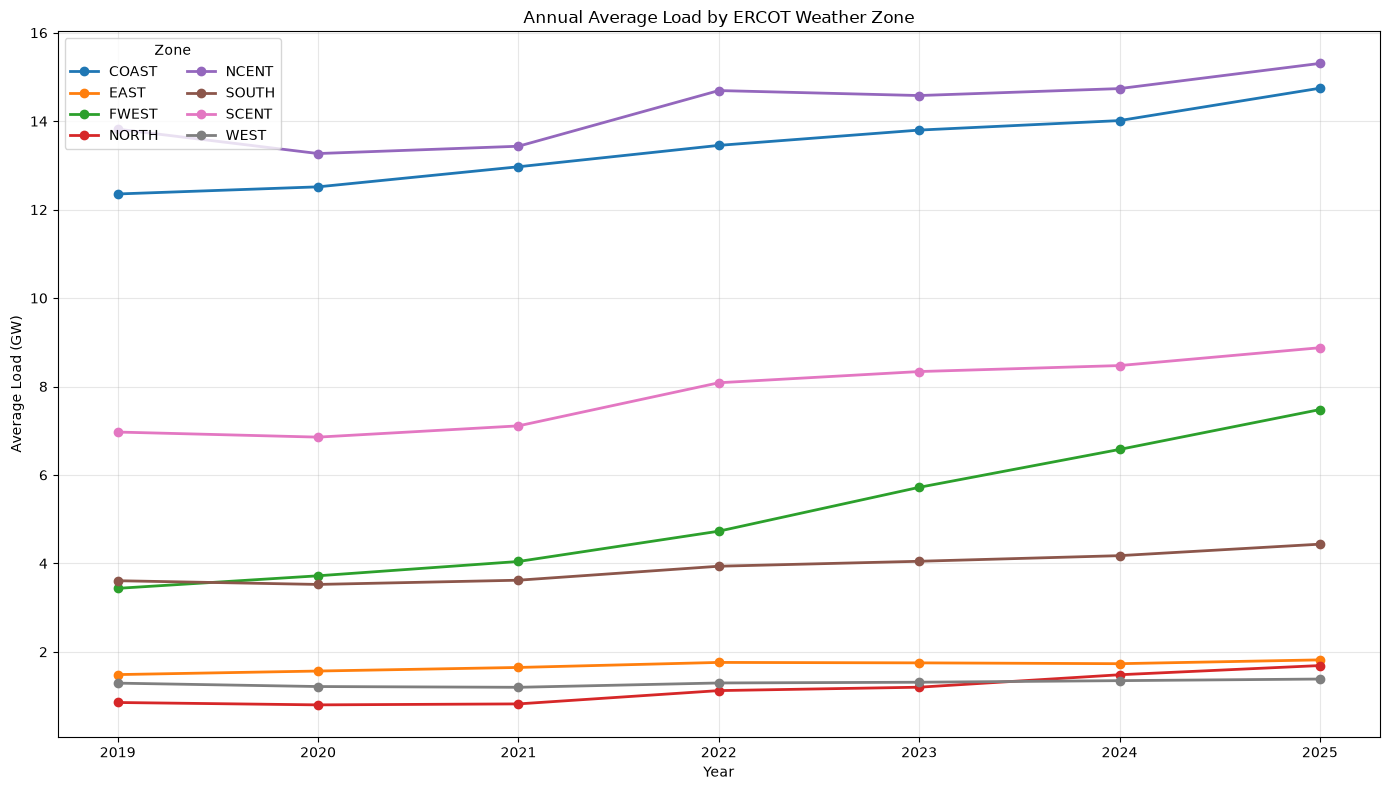

Zone trend figure saved to: report/figures/annual_zone_average_load_trends_2019_2025.png


In [65]:
# Plot and save annual mean-load trajectories for all eight weather zones.

zone_trend_figure, zone_trend_axis = plt.subplots(
    figsize=(14, 8)
)

for zone in zone_columns:
    current_zone_data = annual_zone_average.loc[
        annual_zone_average["zone"] == zone
    ]

    zone_trend_axis.plot(
        current_zone_data["year"],
        current_zone_data["average_load_mw"] / 1_000,
        marker="o",
        linewidth=2,
        label=zone,
    )

zone_trend_axis.set_title(
    "Annual Average Load by ERCOT Weather Zone"
)

zone_trend_axis.set_xlabel("Year")

zone_trend_axis.set_ylabel("Average Load (GW)")

zone_trend_axis.grid(
    alpha=0.3
)

zone_trend_axis.legend(
    title="Zone",
    ncols=2,
)

zone_trend_figure.tight_layout()

zone_trend_figure_path = (
    figures_dir
    / "annual_zone_average_load_trends_2019_2025.png"
)

zone_trend_figure.savefig(
    zone_trend_figure_path,
    dpi=300,
    bbox_inches="tight",
)

plt.show()

print(
    f"Zone trend figure saved to: {zone_trend_figure_path.relative_to(project_root).as_posix()}"
)


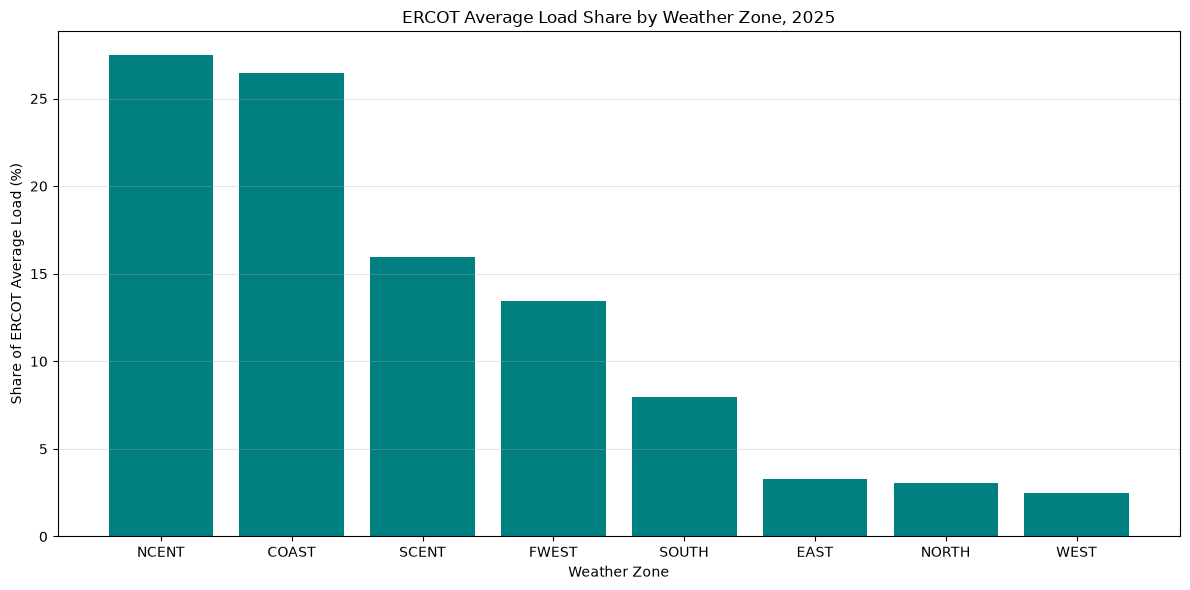

Zone share figure saved to: report/figures/zone_average_load_share_2025.png


In [66]:
# Plot and save 2025 regional shares of average ERCOT system load.

zone_structure_2025 = (
    annual_zone_structure.loc[
        annual_zone_structure["year"] == 2025
    ]
    .sort_values(
        "average_load_share_pct",
        ascending=False,
    )
)

zone_share_figure, zone_share_axis = plt.subplots(
    figsize=(12, 6)
)

zone_share_axis.bar(
    zone_structure_2025["zone"],
    zone_structure_2025["average_load_share_pct"],
    color="teal",
)

zone_share_axis.set_title(
    "ERCOT Average Load Share by Weather Zone, 2025"
)

zone_share_axis.set_xlabel("Weather Zone")

zone_share_axis.set_ylabel("Share of ERCOT Average Load (%)")

zone_share_axis.grid(
    axis="y",
    alpha=0.3,
)

zone_share_figure.tight_layout()

zone_share_figure_path = (
    figures_dir
    / "zone_average_load_share_2025.png"
)

zone_share_figure.savefig(
    zone_share_figure_path,
    dpi=300,
    bbox_inches="tight",
)

plt.show()

print(
    f"Zone share figure saved to: {zone_share_figure_path.relative_to(project_root).as_posix()}"
)


### Regional Load Structure Findings

- **NCENT** and **COAST** were the two largest ERCOT weather zones in 2025, representing approximately **27.46%** and **26.46%** of average system load, respectively (**53.92% combined**).
- The four largest zones—**NCENT, COAST, SCENT, and FWEST**—accounted for approximately **83.27%** of average ERCOT load in 2025.
- **FWEST** experienced the largest absolute and percentage average-load growth between 2019 and 2025: approximately **4.04 GW** (**117.67%**), corresponding to **33.92%** of aggregate regional growth.
- **COAST** and **SCENT** contributed approximately **20.07%** and **16.00%** of aggregate regional load growth, respectively.
- **NORTH** also grew quickly in percentage terms, but its smaller initial load limited its absolute contribution.
- These results identify **where** load growth occurred, not **why**. Economic activity, population, industrial activity, and weather data would be required to evaluate potential causes.


In [67]:
# Measure regional contributions at each year’s **coincident system-peak hour**, not sums of separate regional maxima.
# A coincident-peak decomposition is used because individual zonal peaks can occur at different times.

annual_system_peak_indices = (
    regional_valid_data
    .groupby(
        "year"
    )
    ["ERCOT"]
    .idxmax()
)

annual_system_peak_rows = (
    regional_valid_data.loc[
        annual_system_peak_indices,
        [
            "year",
            "interval_start_local",
            # UTC Hour Ending。
            "HourEnding_utc",
            "ERCOT",
            *zone_columns,
        ],
    ]
    .sort_values("year")
    .reset_index(
        drop=True
    )
)

annual_peak_zone_contribution = annual_system_peak_rows.melt(
    id_vars=[
        "year",
        "interval_start_local",
        # UTC Hour Ending。
        "HourEnding_utc",
        "ERCOT",
    ],
    value_vars=zone_columns,
    var_name="zone",
    value_name="zone_load_mw",
)

annual_peak_zone_contribution["peak_contribution_pct"] = (
    annual_peak_zone_contribution["zone_load_mw"]
    / annual_peak_zone_contribution["ERCOT"]
    * 100
)

annual_peak_zone_contribution = (
    annual_peak_zone_contribution
    .sort_values(
        ["year", "peak_contribution_pct"],
        ascending=[True, False],
    )
    .reset_index(
        drop=True
    )
)

annual_peak_contribution_check = (
    annual_peak_zone_contribution
    .groupby(
        "year",
        as_index=False,
    )
    .agg(
        total_peak_contribution_pct=(
            "peak_contribution_pct",
            "sum",
        )
    )
)

annual_peak_zone_contribution_path = (
    tables_dir
    / "annual_system_peak_zone_contribution_2019_2025.csv"
)

annual_peak_zone_contribution.to_csv(
    annual_peak_zone_contribution_path,
    index=False,
)

display(
    annual_peak_zone_contribution.loc[
        annual_peak_zone_contribution["year"] == 2025
    ]
)

display(annual_peak_contribution_check)

print(
    "Peak contribution table saved to:",
    annual_peak_zone_contribution_path.relative_to(project_root).as_posix(),
)


,year,interval_start_local,HourEnding_utc,ERCOT,zone,zone_load_mw,peak_contribution_pct
48,2025,2025-08-18 17:00:00,2025-08-18 23:00:00+00:00,"83,679.002",NCENT,"26,581.625",31.766
49,2025,2025-08-18 17:00:00,2025-08-18 23:00:00+00:00,"83,679.002",COAST,"22,349.498",26.709
50,2025,2025-08-18 17:00:00,2025-08-18 23:00:00+00:00,"83,679.002",SCENT,"14,519.963",17.352
51,2025,2025-08-18 17:00:00,2025-08-18 23:00:00+00:00,"83,679.002",FWEST,"7,046.247",8.421
52,2025,2025-08-18 17:00:00,2025-08-18 23:00:00+00:00,"83,679.002",SOUTH,"6,508.846",7.778
53,2025,2025-08-18 17:00:00,2025-08-18 23:00:00+00:00,"83,679.002",EAST,"2,888.691",3.452
54,2025,2025-08-18 17:00:00,2025-08-18 23:00:00+00:00,"83,679.002",NORTH,"1,942.521",2.321
55,2025,2025-08-18 17:00:00,2025-08-18 23:00:00+00:00,"83,679.002",WEST,"1,841.612",2.201


,year,total_peak_contribution_pct
0,2019,100.000
1,2020,100.000
2,2021,100.000
3,2022,100.000
4,2023,100.000
5,2024,100.000
6,2025,100.000


Peak contribution table saved to: report/tables/annual_system_peak_zone_contribution_2019_2025.csv


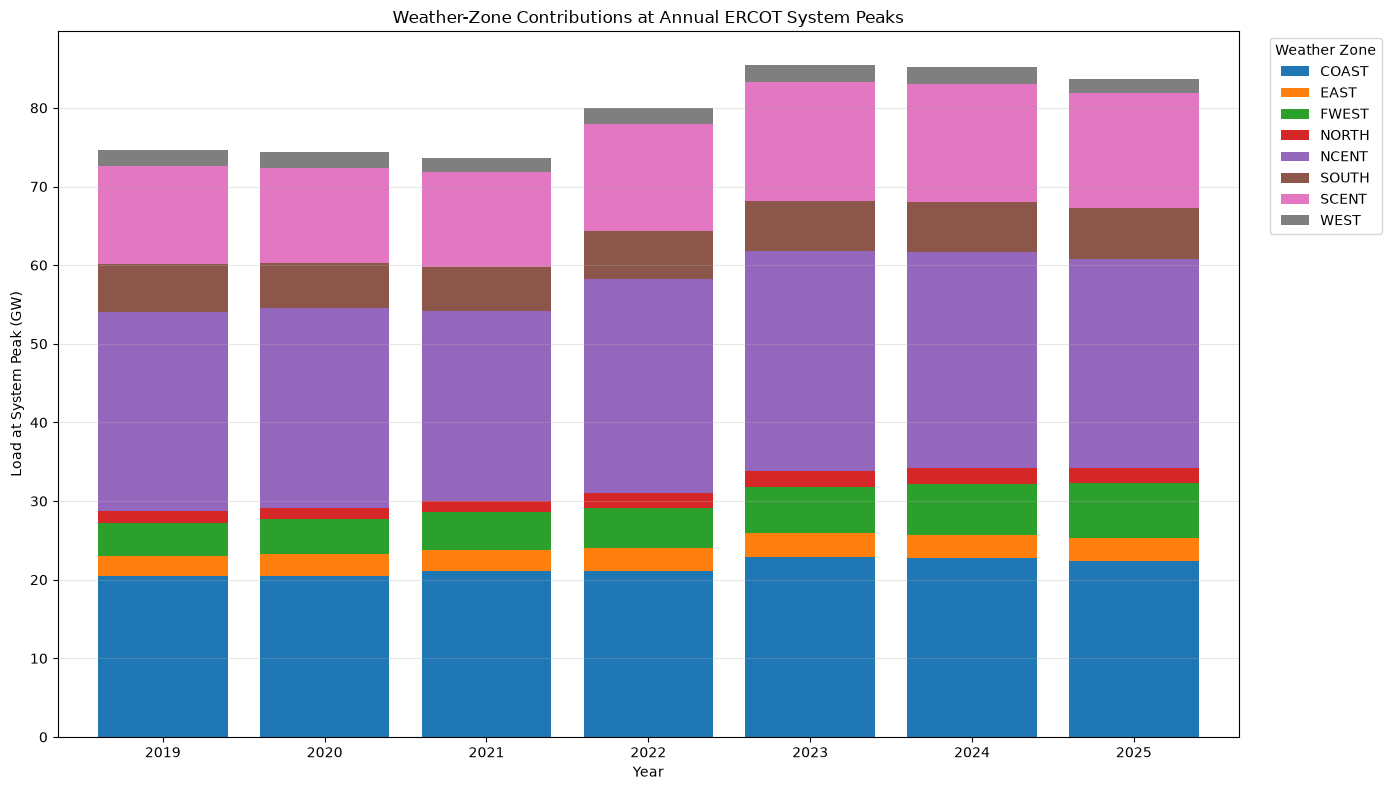

Peak-zone figure saved to: report/figures/annual_system_peak_zone_contributions_2019_2025.png


In [68]:
# Plot the breakdown of regional load at each annual coincident system peak.

annual_peak_zone_matrix = annual_peak_zone_contribution.pivot(
    index="year",
    columns="zone",
    values="zone_load_mw",
)

annual_peak_zone_matrix = annual_peak_zone_matrix[
    zone_columns
]

annual_peak_zone_matrix_gw = (
    annual_peak_zone_matrix
    / 1_000
)

peak_zone_figure, peak_zone_axis = plt.subplots(
    figsize=(14, 8)
)

annual_peak_zone_matrix_gw.plot(
    kind="bar",
    stacked=True,
    ax=peak_zone_axis,
    width=0.8,
)

peak_zone_axis.set_title(
    "Weather-Zone Contributions at Annual ERCOT System Peaks"
)

peak_zone_axis.set_xlabel("Year")

peak_zone_axis.set_ylabel("Load at System Peak (GW)")

peak_zone_axis.tick_params(
    axis="x",
    rotation=0,
)

peak_zone_axis.grid(
    axis="y",
    alpha=0.3,
)

peak_zone_axis.legend(
    title="Weather Zone",
    bbox_to_anchor=(1.02, 1),
    loc="upper left",
)

peak_zone_figure.tight_layout()

peak_zone_figure_path = (
    figures_dir
    / "annual_system_peak_zone_contributions_2019_2025.png"
)

peak_zone_figure.savefig(
    peak_zone_figure_path,
    dpi=300,
    bbox_inches="tight",
)

plt.show()

print(
    f"Peak-zone figure saved to: {peak_zone_figure_path.relative_to(project_root).as_posix()}"
)


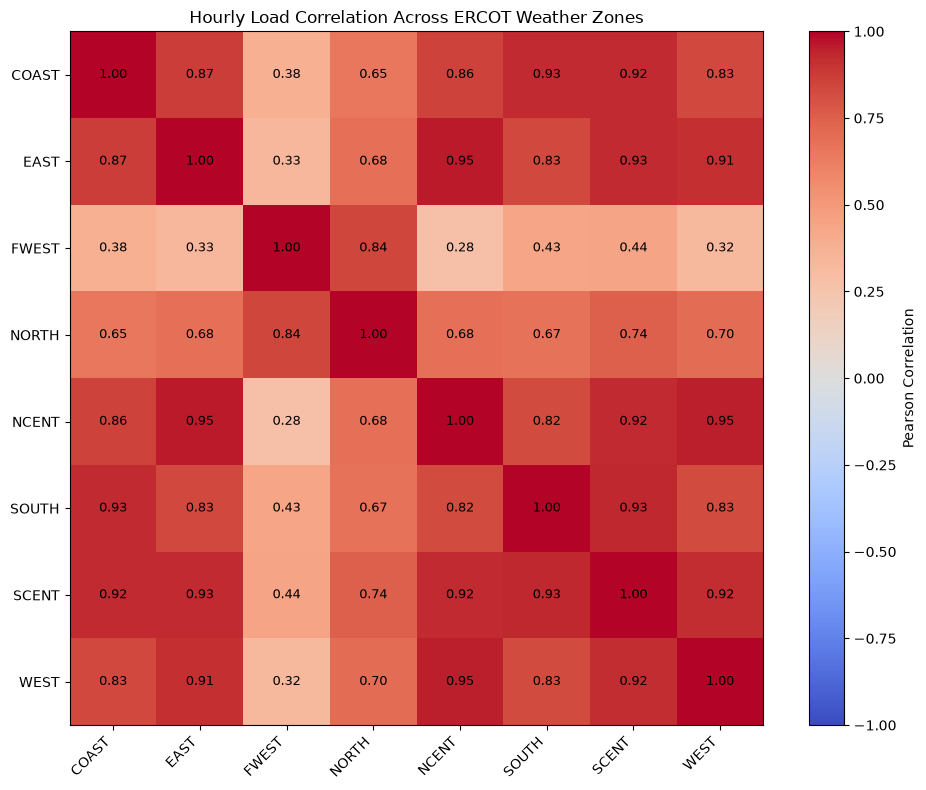

Correlation table saved to: report/tables/zone_load_correlation_matrix_2019_2025.csv
Correlation figure saved to: report/figures/zone_load_correlation_heatmap_2019_2025.png


In [69]:
# Calculate hourly load correlations across eight weather zones and visualize the correlation matrix.
# Pearson correlation measures co-movement but does not establish causal relationships.

zone_correlation_matrix = (
    regional_valid_data[zone_columns]
    .corr()
)

zone_correlation_path = (
    tables_dir
    / "zone_load_correlation_matrix_2019_2025.csv"
)

zone_correlation_matrix.to_csv(
    zone_correlation_path,
    index=True,
)

correlation_figure, correlation_axis = plt.subplots(
    figsize=(10, 8)
)

correlation_image = correlation_axis.imshow(
    zone_correlation_matrix,
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
)

correlation_axis.set_xticks(
    range(len(zone_columns))
)

correlation_axis.set_xticklabels(
    zone_columns,
    rotation=45,
    ha="right",
)

correlation_axis.set_yticks(
    range(len(zone_columns))
)

correlation_axis.set_yticklabels(
    zone_columns
)

for row_position in range(len(zone_columns)):
    for column_position in range(len(zone_columns)):
        correlation_value = zone_correlation_matrix.iloc[
            row_position,
            column_position,
        ]

        correlation_axis.text(
            column_position,
            row_position,
            f"{correlation_value:.2f}",
            ha="center",
            va="center",
            fontsize=9,
            color="black",
        )

correlation_axis.set_title(
    "Hourly Load Correlation Across ERCOT Weather Zones"
)

correlation_colorbar = correlation_figure.colorbar(
    correlation_image,
    ax=correlation_axis,
)

correlation_colorbar.set_label("Pearson Correlation")

correlation_figure.tight_layout()

correlation_figure_path = (
    figures_dir
    / "zone_load_correlation_heatmap_2019_2025.png"
)

correlation_figure.savefig(
    correlation_figure_path,
    dpi=300,
    bbox_inches="tight",
)

plt.show()

print("Correlation table saved to:", zone_correlation_path.relative_to(project_root).as_posix())
print("Correlation figure saved to:", correlation_figure_path.relative_to(project_root).as_posix())


### Regional Peak Contribution and Correlation Findings

- **NCENT** and **COAST** were consistently the largest contributors to annual coincident ERCOT system peaks, together accounting for approximately **58.48%** of the **2025 system peak**.
- **NCENT, COAST, and SCENT** accounted for approximately **75.83%** of the 2025 system peak, indicating a high concentration of coincident peak demand.
- **FWEST** increased its share of the annual system peak from approximately **5.64% in 2019** to **8.42% in 2025**, consistent with its rapid growth in average load.
- Most major regions exhibit strong positive hourly-load correlations, frequently above **0.90**, suggesting that load often rises concurrently across zones and reducing natural regional diversity during high-load periods.
- **FWEST** is an exception: correlations with most major zones are approximately **0.28–0.44**, indicating a materially different hourly pattern.
- **Correlation does not imply causation**. Annual, seasonal, hourly, and weather-related factors all affect the reported correlations.
